# 🩺 Fetal Health Classification
### Machine Learning | Supervised Learning | Multiclass Classification

> Can we classify fetal health as **Normal, Suspect, or Pathological** using cardiotocography (CTG) measurements?

## Introduction

Cardiotocography (CTG) monitors fetal heart rate and uterine contractions. Its measurements can help healthcare professionals assess fetal well-being, but interpreting CTG patterns requires medical expertise.

In this beginner-friendly project, we use a CTG dataset to train simple Machine Learning models that predict one of three fetal health categories: **Normal, Suspect, or Pathological**.

The goal is to practice a clear **classification workflow**: explore the data, split it into training and testing sets, train models, and evaluate their performance. 

**Dataset:** [Fetal Health Classification — Kaggle](https://www.kaggle.com/datasets/andrewmvd/fetal-health-classification)  
**Original data source:** [UCI Cardiotocography](https://archive.ics.uci.edu/dataset/193/cardiotocography)

## Problem Definition

Our task is to predict a **category**, not a continuous number. Therefore, this is a **classification problem**.

| Concept | How it relates to this project |
|---|---|
| **Artificial Intelligence (AI)** | The broad field of intelligent computer systems |
| **Machine Learning (ML)** | Models learn patterns from data |
| **Supervised Learning** | The training data already contains known class labels |
| **Multiclass Classification** | We predict one of three possible classes |

**Target variable: `fetal_health`**

- `1` — **Normal**
- `2` — **Suspect**
- `3` — **Pathological**

These numbers are **class labels**. We compare two algorithms: **Gaussian Naive Bayes** and **Decision Tree**.

## Dataset Overview & Selected Features 📊

The dataset contains **2,126 records** and **22 columns**: **21 input features** and **1 target variable**. All input features are numerical, so categorical encoding is not required.

The table below shows some selected features and their meanings.

| Feature | Meaning |
|---|---|
| `baseline value` | Baseline fetal heart rate |
| `accelerations` | Accelerations of the fetal heart rate |
| `fetal_movement` | Fetal movements |
| `uterine_contractions` | Uterine contractions |
| `light_decelerations` | Light fetal heart rate decelerations |
| `abnormal_short_term_variability` | Abnormal short-term heart rate variability |
| `fetal_health` | **Target: 1 (Normal), 2 (Suspect), 3 (Pathological)** |



## Import Libraries

We use **Pandas**, **Matplotlib**, **Seaborn**, and **Scikit-learn**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

## Load the Dataset

In [2]:
df = pd.read_csv('fetal_health.csv')
df.head()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


## Exploratory Data Analysis (EDA) 🔎

Before training the models, we check the **dataset size**, **missing values**, **duplicate rows**, **summary statistics**, and **class distribution**

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short_term_variability             

In [4]:
print("Rows and columns:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Rows and columns: (2126, 22)
Missing values: 0
Duplicate rows: 13


In [5]:
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset after cleaning:", df.shape)

Dataset after cleaning: (2113, 22)


In [6]:
df["fetal_health"].value_counts().sort_index()

fetal_health
1.0    1646
2.0     292
3.0     175
Name: count, dtype: int64

In [7]:
df.describe()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
count,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000,...,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000
mean,133.304780,0.003188,0.009517,0.004387,0.001901,0.000003,0.000159,46.993848,1.335021,9.795078,...,93.564600,164.099858,4.077142,0.325603,137.454330,134.599621,138.089446,18.907241,0.318504,1.303833
std,9.837451,0.003871,0.046804,0.002941,0.002966,0.000057,0.000592,17.177782,0.884368,18.337073,...,29.562269,17.945175,2.951664,0.707771,16.402026,15.610422,14.478957,29.038766,0.611075,0.614279
min,106.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,12.000000,0.200000,0.000000,...,50.000000,122.000000,0.000000,0.000000,60.000000,73.000000,77.000000,0.000000,-1.000000,1.000000
25%,126.000000,0.000000,0.000000,0.002000,0.000000,0.000000,0.000000,32.000000,0.700000,0.000000,...,67.000000,152.000000,2.000000,0.000000,129.000000,125.000000,129.000000,2.000000,0.000000,1.000000
50%,133.000000,0.002000,0.000000,0.005000,0.000000,0.000000,0.000000,49.000000,1.200000,0.000000,...,93.000000,162.000000,4.000000,0.000000,139.000000,136.000000,139.000000,7.000000,0.000000,1.000000
75%,140.000000,0.006000,0.003000,0.007000,0.003000,0.000000,0.000000,61.000000,1.700000,11.000000,...,120.000000,174.000000,6.000000,0.000000,148.000000,145.000000,148.000000,24.000000,1.000000,1.000000
max,160.000000,0.019000,0.481000,0.015000,0.015000,0.001000,0.005000,87.000000,7.000000,91.000000,...,159.000000,238.000000,18.000000,10.000000,187.000000,182.000000,186.000000,269.000000,1.000000,3.000000


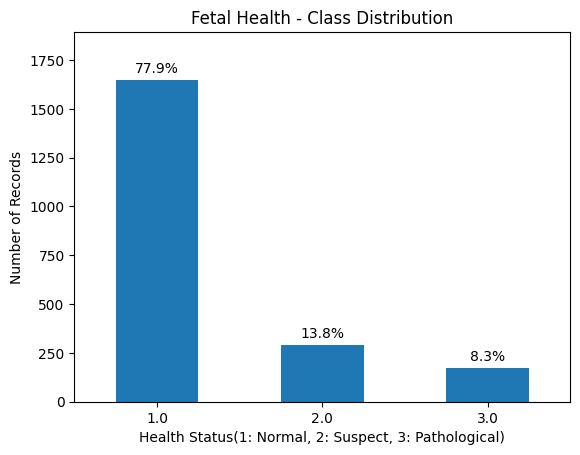

In [17]:

counts = df["fetal_health"].value_counts().sort_index()
ax = counts.plot(kind="bar")

ax.bar_label(ax.containers[0],
             labels=[f"{n/counts.sum():.1%}" for n in counts],
             padding=3)

plt.ylim(0, counts.max() * 1.15)
plt.title("Fetal Health - Class Distribution")
plt.xlabel("Health Status(1: Normal, 2: Suspect, 3: Pathological)")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()


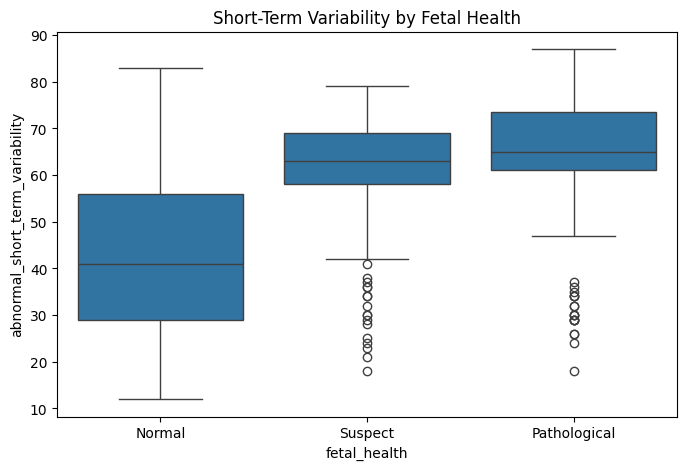

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="fetal_health",
    y="abnormal_short_term_variability"
)

plt.xticks([0, 1, 2], ["Normal", "Suspect", "Pathological"])
plt.title("Short-Term Variability by Fetal Health")
plt.show()

**Observation:**

- **Class imbalance:** The Normal class has many more records than Suspect and Pathological. Therefore, accuracy alone is not enough; we also examine precision, recall, and F1-score
- **Short-term variability:** The distributions differ across the three classes. This feature may help with classification, but a single measurement cannot determine fetal health

## Features & Train–Test Split

We separate the input data from the target variable:

- **X (Features):** All 21 columns except `fetal_health`
- **y (Target):** The `fetal_health` class label
- **80% Training data:** Used to teach the models
- **20% Test data:** Used to evaluate predictions on held-out rows

We use `stratify=y` to keep similar class proportions in both sets. No new features or categorical encoding are needed in this simple project.

In [10]:
X = df.drop("fetal_health", axis=1)
y = df["fetal_health"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (1690, 21)
Test: (423, 21)


## Model Training 🤖

We train two simple classifiers using the **same training and test data**:

- **Gaussian Naive Bayes:** Makes predictions using probability-based assumptions
- **Decision Tree:** Learns decision rules from the data

After fitting each model on `X_train` and `y_train`, we use `X_test` to make predictions.

In [11]:
nb = GaussianNB()
nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)

print("Naive Bayes Accuracy:", round(accuracy_score(y_test, nb_pred), 3))

Naive Bayes Accuracy: 0.797


In [12]:
tree = DecisionTreeClassifier(max_depth=6, random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

print("Decision Tree Accuracy:", round(accuracy_score(y_test, tree_pred), 3))

Decision Tree Accuracy: 0.924


## Model Evaluation 📈

We measure how well each classifier predicts fetal health categories.

| Metric | What does it tell us? |
|---|---|
| **Accuracy** | What proportion of all predictions is correct? |
| **Precision** | When the model predicts a class, how often is it correct? |
| **Recall** | How many real examples of a class does the model find? |
| **F1-score** | How well does the model balance precision and recall? |

`classification_report` shows these results **for each of the three classes**.

In [13]:
print("NAIVE BAYES")
print(classification_report(y_test, nb_pred, target_names=["Normal", "Suspect", "Pathological"]))

print("DECISION TREE")
print(classification_report(y_test, tree_pred, target_names=["Normal", "Suspect", "Pathological"]))

NAIVE BAYES
              precision    recall  f1-score   support

      Normal       0.98      0.82      0.89       330
     Suspect       0.44      0.83      0.57        58
Pathological       0.53      0.57      0.55        35

    accuracy                           0.80       423
   macro avg       0.65      0.74      0.67       423
weighted avg       0.87      0.80      0.82       423

DECISION TREE
              precision    recall  f1-score   support

      Normal       0.93      0.97      0.95       330
     Suspect       0.81      0.66      0.72        58
Pathological       1.00      0.91      0.96        35

    accuracy                           0.92       423
   macro avg       0.91      0.85      0.88       423
weighted avg       0.92      0.92      0.92       423



### Confusion Matrix — Decision Tree

A **Confusion Matrix** helps us see which classes are predicted correctly and which classes are confused with one another.

- **Rows:** Actual classes
- **Columns:** Predicted classes
- **Diagonal:** Correct predictions

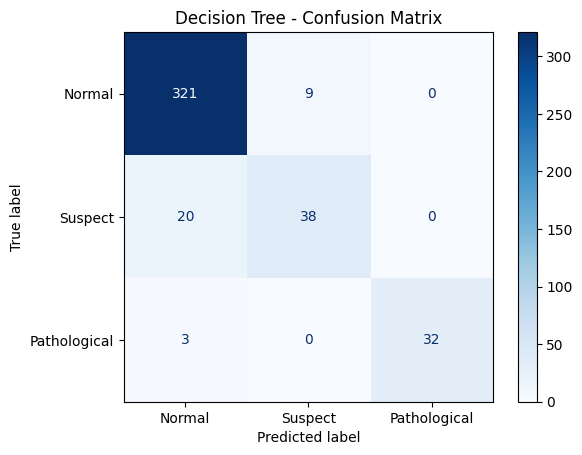

In [14]:
ConfusionMatrixDisplay.from_predictions(
    y_test, tree_pred,
    display_labels=["Normal", "Suspect", "Pathological"],
    cmap="Blues"
)
plt.title("Decision Tree - Confusion Matrix")
plt.show()

### Model Comparison

We compare the two models using **Accuracy** and **Macro F1-score**. Macro F1 gives **equal weight to each class**, which is useful when the classes are imbalanced.

In [15]:
results = pd.DataFrame({
    "Model": ["Naive Bayes", "Decision Tree"],
    "Accuracy": [accuracy_score(y_test, nb_pred), accuracy_score(y_test, tree_pred)],
    "Macro F1": [f1_score(y_test, nb_pred, average="macro"), f1_score(y_test, tree_pred, average="macro")]
})
results.round(3)

,Model,Accuracy,Macro F1
0,Naive Bayes,0.797,0.670
1,Decision Tree,0.924,0.877


### Optional: Feature Importance — Decision Tree

This chart shows the **10 features** the Decision Tree uses most strongly for its predictions.

*Important:* Feature importance describes model behavior; it does **not** prove a medical cause or establish a diagnosis.

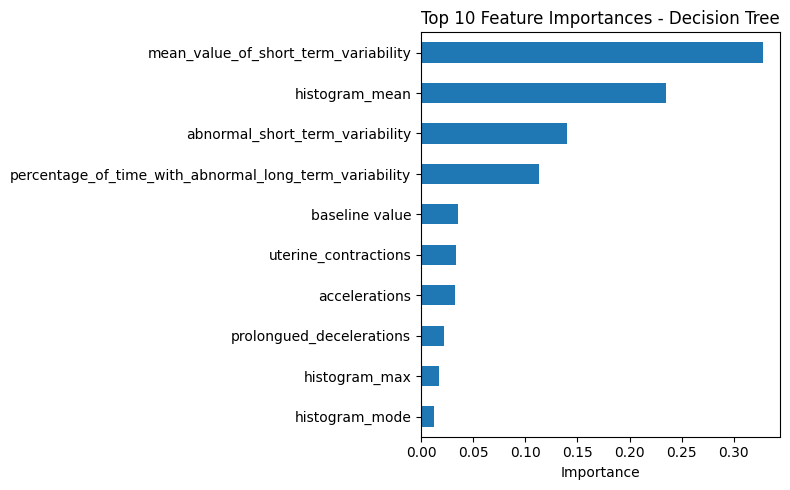

In [16]:
importance = pd.Series(tree.feature_importances_, index=X.columns)
importance.nlargest(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Feature Importances - Decision Tree")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Conclusion & Discussion ✅

In this project, we used a dataset containing **2,126 CTG records and 21 numerical features** to practice **supervised, multiclass classification**. After removing 13 exact duplicate rows, we trained our models on **2,113 records** using an **80/20 stratified train-test split**.

We compared two models: **Gaussian Naive Bayes** and **Decision Tree**.

The **Decision Tree performed better**, achieving **92.4% accuracy** and **0.877 Macro F1**, compared with **79.7% accuracy** and **0.670 Macro F1** for Naive Bayes.

**Accuracy is not the whole story.** The Decision Tree correctly identified **65.5% of Suspect** and **91.4% of Pathological** cases (recall). Because the classes are imbalanced, class-specific evaluation metrics are important.

**Limitations:** The dataset is relatively small. Although exact duplicate rows were removed, patient identifiers are unavailable, so we cannot confirm whether identical measurements belong to the same patients. We used only one train-test split. The models have not been clinically validated and must not be used for medical diagnosis.

**Next steps:** Future improvements could include cross-validation, investigating repeated measurements, and comparing additional models such as Random Forest.

## References & Project Notes

- **Kaggle dataset:** [Fetal Health Classification — andrewmvd](https://www.kaggle.com/datasets/andrewmvd/fetal-health-classification)
- **Original data:** [UCI Cardiotocography](https://archive.ics.uci.edu/dataset/193/cardiotocography)
- **CSV download source:** [GitHub / chrosemo](https://github.com/chrosemo/DATA622-Group3-Final/blob/main/fetal_health.csv)
- **Related publication:** Campos, D. & Bernardes, J. (2000), *Cardiotocography*. UCI Machine Learning Repository. [DOI: 10.24432/C51S4N](https://doi.org/10.24432/C51S4N)